<a href="https://colab.research.google.com/github/merbiji/Computational-Physics/blob/main/PALISBO_PHY161_2_ACTIVITY08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

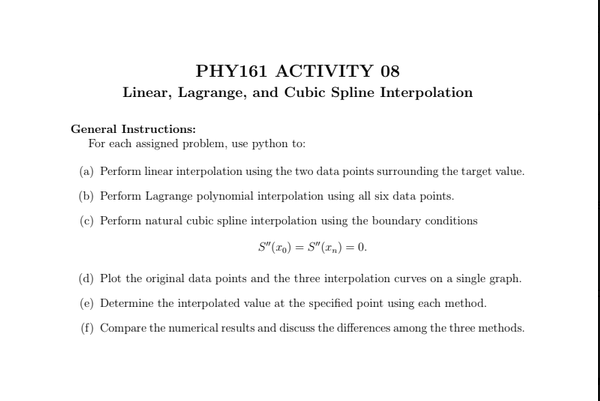

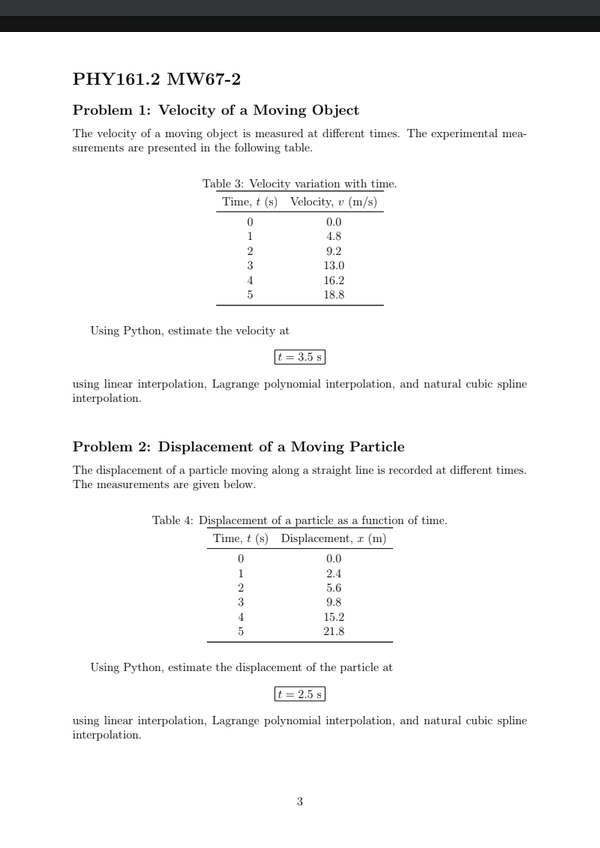


=== Problem 1: value at t = 3.5 s ===
Linear interpolation       : 14.6000
Lagrange polynomial        : 14.6727
Natural cubic spline       : 14.6818
|Linear - Lagrange|        : 0.0727
|Linear - Spline|          : 0.0818
|Lagrange - Spline|        : 0.0092


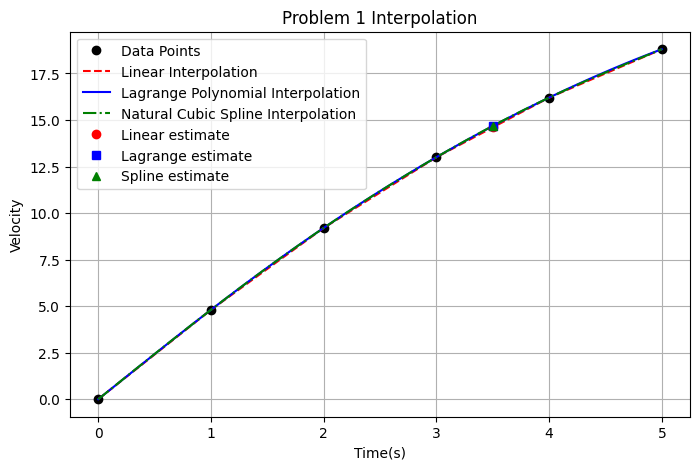


=== Problem 2: value at t = 2.5 s ===
Linear interpolation       : 7.7000
Lagrange polynomial        : 7.5602
Natural cubic spline       : 7.5658
|Linear - Lagrange|        : 0.1398
|Linear - Spline|          : 0.1342
|Lagrange - Spline|        : 0.0056


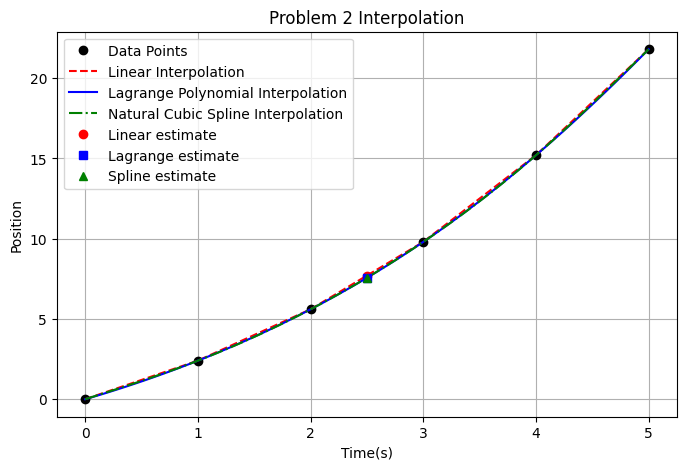

In [5]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, lagrange, CubicSpline


def interpolation(t_data, y_data, target_t, title, type):
  #(a)linear interpolation
  linear_func = interp1d(t_data, y_data, kind='linear')
  val_linear = linear_func(target_t)

  #(b) lagrange
  lagrange_poly = lagrange(t_data, y_data)
  val_lagrange = lagrange_poly(target_t)

  #(c) cubic spline
  spline = CubicSpline(t_data, y_data, bc_type='natural')
  val_spline = spline(target_t)

  # (e) results and (f) differences
  print(f"\n=== {title}: value at t = {target_t} s ===")
  print(f"Linear interpolation       : {val_linear:.4f}")
  print(f"Lagrange polynomial        : {val_lagrange:.4f}")
  print(f"Natural cubic spline       : {val_spline:.4f}")
  print(f"|Linear - Lagrange|        : {abs(val_linear - val_lagrange):.4f}")
  print(f"|Linear - Spline|          : {abs(val_linear - val_spline):.4f}")
  print(f"|Lagrange - Spline|        : {abs(val_lagrange - val_spline):.4f}")

  #(d)
  t_plot = np.linspace(min(t_data), max(t_data), 100)

  plt.figure(figsize=(8, 5))
  plt.plot(t_data, y_data, 'ko', label='Data Points')
  plt.plot(t_plot, linear_func(t_plot), 'r--', label='Linear Interpolation')
  plt.plot(t_plot, lagrange_poly(t_plot), 'b-', label='Lagrange Polynomial Interpolation')
  plt.plot(t_plot, spline(t_plot), 'g-.', label='Natural Cubic Spline Interpolation')

  plt.plot(target_t, val_linear, 'o', color='red', label='Linear estimate')
  plt.plot(target_t, val_lagrange, 's', color='blue', label='Lagrange estimate')
  plt.plot(target_t, val_spline, '^', color='green', label='Spline estimate')

  plt.title(f'{title} Interpolation')
  plt.xlabel('Time(s)')
  plt.ylabel(f'{type}')
  plt.legend()
  plt.grid(True)
  plt.show()

# problem 1
t_vals = np.array([0, 1, 2, 3, 4, 5])
v_vals = np.array([0.0, 4.8, 9.2, 13.0 , 16.2, 18.8])
v_type = "Velocity"
target_t = 3.5
interpolation(t_vals, v_vals, target_t, "Problem 1", v_type)

# problem 2
t_vals1 = np.array([0, 1, 2, 3, 4, 5])
x_vals = np.array([0.0, 2.4, 5.6, 9.8 , 15.2, 21.8])
x_type = "Position"
target_t_2 = 2.5
interpolation(t_vals1, x_vals, target_t_2, "Problem 2", x_type)

f. linear-lagrange and linear-spline has a considerable amount of difference and would suggest that the linear interpolation is the outlier since lagrange-spline has minimal difference.